<a href="https://colab.research.google.com/github/Maee127/Adversarial-Notebooks/blob/master/%2310/Notebook-%2310.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Essay #10: The Shape of the Silence
# Adaptive Attacks Against Three Uncertainty Mechanisms
# ─────────────────────────────────────────────────────────────
# Mechanisms:
#   1. MC Dropout predictive variance
#   2. Evidential Dirichlet uncertainty
#   3. Architecture-native feature geometry
#
# Conditions:
#   1. Clean
#   2. Transferred PGD from a separate surrogate model
#   3. Direct white-box PGD that ignores the uncertainty gate
#   4. Adaptive PGD that causes error while suppressing the gate
#
# Primary metric:
#   Wrong-and-undeferred exposure
#
# Primary comparison:
#   Awareness gap =
#       adaptive wrong-and-undeferred
#       - direct gate-unaware wrong-and-undeferred


In [ ]:
# Notebook parts:
# ─────────────────────────────────────────────────────────────
# Imports and Reproducibility
# Part A: Dataset Splits
# Part B: Shared Architecture
# part C: Four Models
# part D: Evidential Loss
# part E: Training Utilities
# part F: Architecture-native Class Centroids
# part G: Predictions and Uncertainty Signals
# part H: Calibrate Gates
# part I: PGD Projection Helper
# part J: Transferred Attack
# part K: Direct Gate-Unaware Attacks
# part L: Adaptive Gate-Aware Attacks
# Part M: Attack validity checks
# part N: Evaluation
# part O: Select Lambda Without Touching Final Evaluation
# part P: Final Untouched Evaluation
# part Q: Final attack-validity report
# part R: Calculate the Two Gaps
# part S: Publication-Ready Result Table
# part T: Main Visualization
# part U: Wareness-Gap Visualization
# part V: Automatic Factual Summary
# part W: Save Complete Experiment Metadata
# ─────────────────────────────────────────────────────────────

In [1]:
# ─────────────────────────────────────────────────────────────
# Imports and Reproducibility
# ─────────────────────────────────────────────────────────────

from __future__ import annotations

import json
import math
import random
from pathlib import Path
from typing import Callable, Literal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset, random_split
from torchvision import datasets, transforms


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 17
NUM_CLASSES = 10

TRAIN_BATCH_SIZE = 128
EVAL_BATCH_SIZE = 128

EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

TARGET_DEFERRAL = 0.25

EPSILON = 8 / 255
STEP_SIZE = 2 / 255
PGD_STEPS = 20

MC_ATTACK_PASSES = 5
MC_EVAL_PASSES = 30

# Used only for choosing the adaptive trade-off.
# Lambda tuning must use the same attack length as final evaluation.
TUNING_STEPS = PGD_STEPS
TUNING_EXAMPLES = 512
# Zero is the matched gate-unaware baseline.
# Smaller values are necessary because every mechanism previously
# selected the smallest available value.
LAMBDA_CANDIDATES = [
    0.0,
    0.001,
    0.0025,
    0.005,
    0.01,
    0.025,
    0.05,
]

CHECKPOINT_DIR = Path("essay10_checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

RESULTS_DIR = Path("essay10_results_corrected")
RESULTS_DIR.mkdir(exist_ok=True)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

print(f"Device: {DEVICE}")
print(f"PyTorch: {torch.__version__}")


Device: cuda
PyTorch: 2.11.0+cu130


In [2]:
# ─────────────────────────────────────────────────────────────
# Part A: Dataset Splits
# The attacks operate in pixel space, so the dataset uses only ToTensor(). Normalization happens inside each model.
# ─────────────────────────────────────────────────────────────
transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

# Test-set protocol:
#   1,500 images: clean threshold calibration
#   1,000 images: adaptive lambda development
#   7,500 images: untouched final evaluation
#
# The final evaluation set is not used for calibration or lambda selection.

calibration_size = 1_500
attack_dev_size = 1_000
evaluation_size = len(test_dataset) - calibration_size - attack_dev_size

split_generator = torch.Generator().manual_seed(SEED)

calibration_dataset, attack_dev_dataset, evaluation_dataset = random_split(
    test_dataset,
    [calibration_size, attack_dev_size, evaluation_size],
    generator=split_generator,
)

tuning_dataset = Subset(
    attack_dev_dataset,
    list(range(min(TUNING_EXAMPLES, len(attack_dev_dataset)))),
)

train_loader = DataLoader(
    train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    generator=torch.Generator().manual_seed(SEED),
)

train_reference_loader = DataLoader(
    train_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

calibration_loader = DataLoader(
    calibration_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

attack_dev_loader = DataLoader(
    attack_dev_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

tuning_loader = DataLoader(
    tuning_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

evaluation_loader = DataLoader(
    evaluation_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

print(
    {
        "train": len(train_dataset),
        "calibration": len(calibration_dataset),
        "attack_development": len(attack_dev_dataset),
        "lambda_tuning_subset": len(tuning_dataset),
        "final_evaluation": len(evaluation_dataset),
    }
)


100%|██████████| 170M/170M [50:37<00:00, 56.1kB/s]


{'train': 50000, 'calibration': 1500, 'attack_development': 1000, 'lambda_tuning_subset': 512, 'final_evaluation': 7500}


In [3]:
# ─────────────────────────────────────────────────────────────
# Part B: Shared Architecture
# Using a common backbone reduces unnecessary architectural differences between the mechanisms.
# ─────────────────────────────────────────────────────────────

CIFAR_MEAN = torch.tensor(
    [0.4914, 0.4822, 0.4465],
    dtype=torch.float32,
).view(1, 3, 1, 1)

CIFAR_STD = torch.tensor(
    [0.2023, 0.1994, 0.2010],
    dtype=torch.float32,
).view(1, 3, 1, 1)


def normalize_images(x: torch.Tensor) -> torch.Tensor:
    mean = CIFAR_MEAN.to(device=x.device, dtype=x.dtype)
    std = CIFAR_STD.to(device=x.device, dtype=x.dtype)
    return (x - mean) / std


class FeatureBackbone(nn.Module):
    def __init__(self, dropout_probability: float = 0.0) -> None:
        super().__init__()

        self.dropout_probability = dropout_probability

        self.block1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.projection = nn.Linear(256, 128)

    def forward(
        self,
        x: torch.Tensor,
        *,
        stochastic_dropout: bool = False,
    ) -> torch.Tensor:
        x = normalize_images(x)

        x = self.block1(x)
        x = F.dropout2d(
            x,
            p=self.dropout_probability,
            training=stochastic_dropout,
        )

        x = self.block2(x)
        x = F.dropout2d(
            x,
            p=self.dropout_probability,
            training=stochastic_dropout,
        )

        x = self.block3(x)
        x = torch.flatten(x, 1)
        x = self.projection(x)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=self.dropout_probability,
            training=stochastic_dropout,
        )

        return x


In [4]:
# ─────────────────────────────────────────────────────────────
# Part C: Four Models
# ─────────────────────────────────────────────────────────────

class StandardCNN(nn.Module):
    """Independent surrogate used to generate transferred PGD."""

    def __init__(self) -> None:
        super().__init__()
        self.backbone = FeatureBackbone(dropout_probability=0.0)
        self.classifier = nn.Linear(128, NUM_CLASSES)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.backbone(x)
        return self.classifier(features)


class MCDropoutCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.backbone = FeatureBackbone(dropout_probability=0.30)
        self.classifier = nn.Linear(128, NUM_CLASSES)

    def forward(
        self,
        x: torch.Tensor,
        *,
        stochastic: bool = False,
    ) -> torch.Tensor:
        features = self.backbone(
            x,
            stochastic_dropout=stochastic,
        )
        return self.classifier(features)


class EvidentialCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.backbone = FeatureBackbone(dropout_probability=0.0)
        self.evidence_head = nn.Linear(128, NUM_CLASSES)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        features = self.backbone(x)
        evidence = F.softplus(self.evidence_head(features))

        # Dirichlet parameters must be greater than one when
        # evidence is defined as alpha - 1.
        alpha = evidence + 1.0
        return alpha


class GeometryCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.backbone = FeatureBackbone(dropout_probability=0.0)
        self.classifier = nn.Linear(128, NUM_CLASSES)

    def forward(
        self,
        x: torch.Tensor,
        *,
        return_features: bool = False,
    ):
        features = self.backbone(x)
        logits = self.classifier(features)

        if return_features:
            return logits, features

        return logits


In [5]:
# ─────────────────────────────────────────────────────────────
# Part D: Evidential Loss
# ─────────────────────────────────────────────────────────────

def dirichlet_kl_to_uniform(alpha: torch.Tensor) -> torch.Tensor:
    """KL[Dir(alpha) || Dir(1)]."""

    num_classes = alpha.shape[1]
    beta = torch.ones_like(alpha)

    alpha_sum = alpha.sum(dim=1, keepdim=True)
    beta_sum = beta.sum(dim=1, keepdim=True)

    log_normalizer_ratio = (
        torch.lgamma(alpha_sum)
        - torch.lgamma(alpha).sum(dim=1, keepdim=True)
        - torch.lgamma(beta_sum)
        + torch.lgamma(beta).sum(dim=1, keepdim=True)
    )

    digamma_term = (
        (alpha - beta)
        * (torch.digamma(alpha) - torch.digamma(alpha_sum))
    ).sum(dim=1, keepdim=True)

    return (log_normalizer_ratio + digamma_term).squeeze(1)


def evidential_classification_loss(
    alpha: torch.Tensor,
    labels: torch.Tensor,
    *,
    epoch: int,
    annealing_epochs: int = 10,
) -> torch.Tensor:
    one_hot = F.one_hot(
        labels,
        num_classes=NUM_CLASSES,
    ).float()

    strength = alpha.sum(dim=1, keepdim=True)

    expected_cross_entropy = (
        one_hot
        * (
            torch.digamma(strength)
            - torch.digamma(alpha)
        )
    ).sum(dim=1)

    # Do not penalize evidence assigned to the correct class.
    adjusted_alpha = one_hot + (1.0 - one_hot) * alpha

    annealing_coefficient = min(
        1.0,
        epoch / float(annealing_epochs),
    )

    regularization = dirichlet_kl_to_uniform(adjusted_alpha)

    return (
        expected_cross_entropy
        + annealing_coefficient * 0.01 * regularization
    ).mean()


In [6]:
# ─────────────────────────────────────────────────────────────
# Part E: Training Utilities
# ─────────────────────────────────────────────────────────────

ModelKind = Literal[
    "surrogate",
    "mc_dropout",
    "evidential",
    "geometry",
]


def train_model(
    model: nn.Module,
    *,
    model_kind: ModelKind,
    checkpoint_name: str,
) -> nn.Module:
    checkpoint_path = CHECKPOINT_DIR / checkpoint_name

    if checkpoint_path.exists():
        print(f"Loading {checkpoint_path}")
        state = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=True,
        )
        model.load_state_dict(state)
        return model.to(DEVICE)

    optimizer = optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS,
    )

    model = model.to(DEVICE)

    for epoch in range(1, EPOCHS + 1):
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            if model_kind == "evidential":
                alpha = model(images)
                loss = evidential_classification_loss(
                    alpha,
                    labels,
                    epoch=epoch,
                )
                probabilities = alpha / alpha.sum(
                    dim=1,
                    keepdim=True,
                )
            elif model_kind == "mc_dropout":
                logits = model(images, stochastic=True)
                loss = F.cross_entropy(logits, labels)
                probabilities = F.softmax(logits, dim=1)
            else:
                logits = model(images)
                loss = F.cross_entropy(logits, labels)
                probabilities = F.softmax(logits, dim=1)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (
                probabilities.argmax(dim=1) == labels
            ).sum().item()
            total += labels.size(0)

        scheduler.step()

        print(
            f"{checkpoint_name} | "
            f"epoch {epoch:02d}/{EPOCHS} | "
            f"loss {running_loss / total:.4f} | "
            f"train accuracy {100 * correct / total:.2f}%"
        )

    torch.save(model.state_dict(), checkpoint_path)
    print(f"Saved {checkpoint_path}")

    return model


surrogate_model = train_model(
    StandardCNN(),
    model_kind="surrogate",
    checkpoint_name="surrogate_cnn.pth",
)

mc_model = train_model(
    MCDropoutCNN(),
    model_kind="mc_dropout",
    checkpoint_name="mc_dropout_cnn.pth",
)

evidential_model = train_model(
    EvidentialCNN(),
    model_kind="evidential",
    checkpoint_name="evidential_cnn.pth",
)

geometry_model = train_model(
    GeometryCNN(),
    model_kind="geometry",
    checkpoint_name="geometry_cnn.pth",
)

for model in [
    surrogate_model,
    mc_model,
    evidential_model,
    geometry_model,
]:
    model.eval()


surrogate_cnn.pth | epoch 01/20 | loss 1.2919 | train accuracy 52.62%
surrogate_cnn.pth | epoch 02/20 | loss 0.8707 | train accuracy 68.79%
surrogate_cnn.pth | epoch 03/20 | loss 0.7140 | train accuracy 74.77%
surrogate_cnn.pth | epoch 04/20 | loss 0.5949 | train accuracy 79.17%
surrogate_cnn.pth | epoch 05/20 | loss 0.5060 | train accuracy 82.29%
surrogate_cnn.pth | epoch 06/20 | loss 0.4352 | train accuracy 84.75%
surrogate_cnn.pth | epoch 07/20 | loss 0.3735 | train accuracy 87.11%
surrogate_cnn.pth | epoch 08/20 | loss 0.3159 | train accuracy 89.03%
surrogate_cnn.pth | epoch 09/20 | loss 0.2682 | train accuracy 90.66%
surrogate_cnn.pth | epoch 10/20 | loss 0.2077 | train accuracy 92.83%
surrogate_cnn.pth | epoch 11/20 | loss 0.1662 | train accuracy 94.33%
surrogate_cnn.pth | epoch 12/20 | loss 0.1206 | train accuracy 96.04%
surrogate_cnn.pth | epoch 13/20 | loss 0.0861 | train accuracy 97.32%
surrogate_cnn.pth | epoch 14/20 | loss 0.0583 | train accuracy 98.42%
surrogate_cnn.pth | 

In [7]:
# ─────────────────────────────────────────────────────────────
# Part F: Architecture-native Class Centroids
# The architecture-native signal measures how far an input’s normalized internal feature representation lies from its nearest learned class centroid.
# ─────────────────────────────────────────────────────────────

@torch.no_grad()
def compute_class_centroids(
    model: GeometryCNN,
    loader: DataLoader,
) -> torch.Tensor:
    model.eval()

    feature_sums = torch.zeros(
        NUM_CLASSES,
        128,
        device=DEVICE,
    )

    class_counts = torch.zeros(
        NUM_CLASSES,
        device=DEVICE,
    )

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        _, features = model(
            images,
            return_features=True,
        )

        features = F.normalize(features, p=2, dim=1)

        for class_index in range(NUM_CLASSES):
            mask = labels == class_index

            if mask.any():
                feature_sums[class_index] += features[mask].sum(dim=0)
                class_counts[class_index] += mask.sum()

    centroids = feature_sums / class_counts.unsqueeze(1).clamp_min(1.0)
    centroids = F.normalize(centroids, p=2, dim=1)

    return centroids


centroid_path = CHECKPOINT_DIR / "geometry_centroids.pt"

if centroid_path.exists():
    class_centroids = torch.load(
        centroid_path,
        map_location=DEVICE,
        weights_only=True,
    )
else:
    class_centroids = compute_class_centroids(
        geometry_model,
        train_reference_loader,
    )
    torch.save(class_centroids, centroid_path)

print("Class centroids:", class_centroids.shape)


Class centroids: torch.Size([10, 128])


In [8]:
# ─────────────────────────────────────────────────────────────
# Part G: Predictions and Uncertainty Signals
# ─────────────────────────────────────────────────────────────

def mc_predictive_distribution(
    model: MCDropoutCNN,
    images: torch.Tensor,
    *,
    passes: int,
) -> tuple[torch.Tensor, torch.Tensor]:
    probability_samples = torch.stack(
        [
            F.softmax(
                model(images, stochastic=True),
                dim=1,
            )
            for _ in range(passes)
        ],
        dim=0,
    )

    mean_probabilities = probability_samples.mean(dim=0)

    # Maximum class-wise predictive variance.
    uncertainty = probability_samples.var(
        dim=0,
        unbiased=False,
    ).max(dim=1).values

    return mean_probabilities, uncertainty


def evidential_predictive_distribution(
    model: EvidentialCNN,
    images: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor]:
    alpha = model(images)
    strength = alpha.sum(dim=1, keepdim=True)

    probabilities = alpha / strength

    # Standard Dirichlet uncertainty K / S.
    uncertainty = NUM_CLASSES / strength.squeeze(1)

    return probabilities, uncertainty


def geometry_predictive_distribution(
    model: GeometryCNN,
    images: torch.Tensor,
    centroids: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor]:
    logits, features = model(
        images,
        return_features=True,
    )

    probabilities = F.softmax(logits, dim=1)
    normalized_features = F.normalize(features, p=2, dim=1)

    squared_distances = torch.cdist(
        normalized_features,
        centroids,
        p=2,
    ).pow(2)

    # Large distance from every class centroid means uncertainty.
    uncertainty = squared_distances.min(dim=1).values

    return probabilities, uncertainty


def get_prediction_and_uncertainty(
    model_kind: Literal["mc_dropout", "evidential", "geometry"],
    model: nn.Module,
    images: torch.Tensor,
    *,
    mc_passes: int,
) -> tuple[torch.Tensor, torch.Tensor]:
    if model_kind == "mc_dropout":
        return mc_predictive_distribution(
            model,
            images,
            passes=mc_passes,
        )

    if model_kind == "evidential":
        return evidential_predictive_distribution(
            model,
            images,
        )

    if model_kind == "geometry":
        return geometry_predictive_distribution(
            model,
            images,
            class_centroids,
        )

    raise ValueError(f"Unknown model kind: {model_kind}")


In [9]:
# ─────────────────────────────────────────────────────────────
# PArt H: Calibrate Gates
# All three signals use the same rule: larger uncertainty means greater reason to defer.
# ─────────────────────────────────────────────────────────────

@torch.no_grad()
def collect_uncertainty_values(
    model_kind: Literal["mc_dropout", "evidential", "geometry"],
    model: nn.Module,
    loader: DataLoader,
) -> np.ndarray:
    model.eval()

    values: list[np.ndarray] = []

    for images, _ in loader:
        images = images.to(DEVICE, non_blocking=True)

        _, uncertainty = get_prediction_and_uncertainty(
            model_kind,
            model,
            images,
            mc_passes=MC_EVAL_PASSES,
        )

        values.append(uncertainty.cpu().numpy())

    return np.concatenate(values)


def calibrate_gate(
    model_kind: Literal["mc_dropout", "evidential", "geometry"],
    model: nn.Module,
) -> dict[str, float]:
    uncertainty_values = collect_uncertainty_values(
        model_kind,
        model,
        calibration_loader,
    )

    threshold = float(
        np.quantile(
            uncertainty_values,
            1.0 - TARGET_DEFERRAL,
        )
    )

    scale = float(np.std(uncertainty_values))

    if scale < 1e-8:
        scale = 1.0

    return {
        "threshold": threshold,
        "scale": scale,
        "mean": float(np.mean(uncertainty_values)),
        "median": float(np.median(uncertainty_values)),
    }


calibration = {
    "mc_dropout": calibrate_gate(
        "mc_dropout",
        mc_model,
    ),
    "evidential": calibrate_gate(
        "evidential",
        evidential_model,
    ),
    "geometry": calibrate_gate(
        "geometry",
        geometry_model,
    ),
}

print(json.dumps(calibration, indent=2))

with open(
    RESULTS_DIR / "calibration.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(calibration, file, indent=2)


{
  "mc_dropout": {
    "threshold": 0.03991667553782463,
    "scale": 0.02187621407210827,
    "mean": 0.024713490158319473,
    "median": 0.022069226950407028
  },
  "evidential": {
    "threshold": 0.1761368215084076,
    "scale": 0.10930821299552917,
    "mean": 0.148169606924057,
    "median": 0.12059633433818817
  },
  "geometry": {
    "threshold": 0.14276736974716187,
    "scale": 0.056780651211738586,
    "mean": 0.10985779017210007,
    "median": 0.0993223488330841
  }
}


In [10]:
# ─────────────────────────────────────────────────────────────
# Part I: PGD Projection Helper
# ─────────────────────────────────────────────────────────────

def project_linf(
    candidate: torch.Tensor,
    original: torch.Tensor,
    *,
    epsilon: float,
) -> torch.Tensor:
    perturbation = torch.clamp(
        candidate - original,
        min=-epsilon,
        max=epsilon,
    )

    return torch.clamp(
        original + perturbation,
        min=0.0,
        max=1.0,
    )


In [11]:
# ─────────────────────────────────────────────────────────────
# Part J: Transferred Attack
# This attack is generated only against the separate surrogate model.
# ─────────────────────────────────────────────────────────────

def transferred_pgd(
    surrogate: StandardCNN,
    images: torch.Tensor,
    labels: torch.Tensor,
    *,
    epsilon: float = EPSILON,
    step_size: float = STEP_SIZE,
    steps: int = PGD_STEPS,
) -> torch.Tensor:
    surrogate.eval()

    original = images.detach()
    adversarial = original.clone()

    for _ in range(steps):
        adversarial.requires_grad_(True)

        logits = surrogate(adversarial)
        loss = F.cross_entropy(logits, labels)

        gradient = torch.autograd.grad(
            loss,
            adversarial,
            only_inputs=True,
        )[0]

        candidate = (
            adversarial.detach()
            + step_size * gradient.sign()
        )

        adversarial = project_linf(
            candidate,
            original,
            epsilon=epsilon,
        ).detach()

    return adversarial


In [12]:
# ─────────────────────────────────────────────────────────────
# Part K: Direct Gate-Unaware Attacks
# These attacks have white-box access to the classifier but do not optimize the uncertainty signal.
# ─────────────────────────────────────────────────────────────

def direct_classifier_loss(
    model_kind: Literal["mc_dropout", "evidential", "geometry"],
    model: nn.Module,
    images: torch.Tensor,
    labels: torch.Tensor,
) -> torch.Tensor:
    probabilities, _ = get_prediction_and_uncertainty(
        model_kind,
        model,
        images,
        mc_passes=MC_ATTACK_PASSES,
    )

    return F.nll_loss(
        torch.log(probabilities.clamp_min(1e-10)),
        labels,
    )


def direct_whitebox_pgd(
    model_kind: Literal["mc_dropout", "evidential", "geometry"],
    model: nn.Module,
    images: torch.Tensor,
    labels: torch.Tensor,
    *,
    epsilon: float = EPSILON,
    step_size: float = STEP_SIZE,
    steps: int = PGD_STEPS,
) -> torch.Tensor:
    model.eval()

    original = images.detach()
    adversarial = original.clone()

    for _ in range(steps):
        adversarial.requires_grad_(True)

        loss = direct_classifier_loss(
            model_kind,
            model,
            adversarial,
            labels,
        )

        gradient = torch.autograd.grad(
            loss,
            adversarial,
            only_inputs=True,
        )[0]

        candidate = (
            adversarial.detach()
            + step_size * gradient.sign()
        )

        adversarial = project_linf(
            candidate,
            original,
            epsilon=epsilon,
        ).detach()

    return adversarial


In [13]:
# ─────────────────────────────────────────────────────────────
# Part L: Adaptive Gate-Aware Attacks
# For all mechanisms, the attack maximizes:
# L_classification - lambda * U(x) / calibration scale
# Because the attack uses gradient ascent, this increases error while reducing the uncertainty signal.
# ─────────────────────────────────────────────────────────────

def geometry_wrong_class_distance(
    model: GeometryCNN,
    images: torch.Tensor,
    labels: torch.Tensor,
    centroids: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor]:
    """
    Return classification probabilities and distance to the nearest
    incorrect-class centroid.

    Unlike the gate's ordinary uncertainty signal, this explicitly
    excludes the true-class centroid. Therefore, the adaptive attack
    cannot suppress uncertainty merely by moving an image closer to
    its correct class.
    """
    logits, features = model(
        images,
        return_features=True,
    )

    probabilities = F.softmax(logits, dim=1)
    normalized_features = F.normalize(
        features,
        p=2,
        dim=1,
    )

    squared_distances = torch.cdist(
        normalized_features,
        centroids,
        p=2,
    ).pow(2)

    true_class_mask = F.one_hot(
        labels,
        num_classes=NUM_CLASSES,
    ).bool()

    incorrect_distances = squared_distances.masked_fill(
        true_class_mask,
        float("inf"),
    )

    nearest_wrong_distance = incorrect_distances.min(
        dim=1
    ).values

    return probabilities, nearest_wrong_distance


def adaptive_gate_aware_pgd(
    model_kind: Literal[
        "mc_dropout",
        "evidential",
        "geometry",
    ],
    model: nn.Module,
    images: torch.Tensor,
    labels: torch.Tensor,
    *,
    lam: float,
    uncertainty_scale: float,
    epsilon: float = EPSILON,
    step_size: float = STEP_SIZE,
    steps: int = PGD_STEPS,
) -> torch.Tensor:
    """
    Maximize classification error while suppressing the mechanism's
    warning signal.

    MC Dropout:
        increase classification loss and reduce predictive variance.

    Evidential:
        increase classification loss and reduce Dirichlet uncertainty.

    Feature Geometry:
        increase classification loss and reduce distance to an
        incorrect-class centroid.
    """
    model.eval()

    original = images.detach()
    adversarial = original.clone()

    scale = max(uncertainty_scale, 1e-8)

    for _ in range(steps):
        adversarial.requires_grad_(True)

        if model_kind == "geometry":
            probabilities, suppression_signal = (
                geometry_wrong_class_distance(
                    model,
                    adversarial,
                    labels,
                    class_centroids,
                )
            )
        else:
            probabilities, suppression_signal = (
                get_prediction_and_uncertainty(
                    model_kind,
                    model,
                    adversarial,
                    mc_passes=MC_ATTACK_PASSES,
                )
            )

        classification_loss = F.nll_loss(
            torch.log(
                probabilities.clamp_min(1e-10)
            ),
            labels,
        )

        normalized_suppression_signal = (
            suppression_signal / scale
        ).mean()

        # Gradient ascent:
        #
        # 1. classification_loss increases;
        # 2. the relevant warning signal decreases.
        objective = (
            classification_loss
            - lam * normalized_suppression_signal
        )

        gradient = torch.autograd.grad(
            objective,
            adversarial,
            only_inputs=True,
        )[0]

        candidate = (
            adversarial.detach()
            + step_size * gradient.sign()
        )

        adversarial = project_linf(
            candidate,
            original,
            epsilon=epsilon,
        ).detach()

    return adversarial


In [14]:
# ─────────────────────────────────────────────────────────────
# Part M: Attack validity checks
# ─────────────────────────────────────────────────────────────

ATTACK_SANITY: dict[str, dict[str, float]] = {}


def verify_adversarial_batch(
    original_images: torch.Tensor,
    adversarial_images: torch.Tensor,
    *,
    attack_name: str,
    epsilon: float = EPSILON,
    tolerance: float = 1e-6,
) -> None:
    """
    Verify that an adversarial batch:

    1. contains only finite values;
    2. remains inside valid pixel range [0, 1];
    3. respects the L-infinity perturbation budget.
    """
    if not torch.isfinite(adversarial_images).all():
        raise AssertionError(
            f"{attack_name}: adversarial images contain NaN or infinity."
        )

    minimum_pixel = adversarial_images.min().item()
    maximum_pixel = adversarial_images.max().item()

    max_linf = (
        adversarial_images - original_images
    ).abs().amax().item()

    if minimum_pixel < -tolerance:
        raise AssertionError(
            f"{attack_name}: minimum pixel {minimum_pixel:.8f} "
            "is below zero."
        )

    if maximum_pixel > 1.0 + tolerance:
        raise AssertionError(
            f"{attack_name}: maximum pixel {maximum_pixel:.8f} "
            "is above one."
        )

    if max_linf > epsilon + tolerance:
        raise AssertionError(
            f"{attack_name}: L-inf perturbation "
            f"{max_linf:.8f} exceeds epsilon "
            f"{epsilon:.8f}."
        )

    previous = ATTACK_SANITY.get(
        attack_name,
        {
            "minimum_pixel": float("inf"),
            "maximum_pixel": float("-inf"),
            "maximum_linf": 0.0,
            "epsilon": epsilon,
        },
    )

    ATTACK_SANITY[attack_name] = {
        "minimum_pixel": min(
            previous["minimum_pixel"],
            minimum_pixel,
        ),
        "maximum_pixel": max(
            previous["maximum_pixel"],
            maximum_pixel,
        ),
        "maximum_linf": max(
            previous["maximum_linf"],
            max_linf,
        ),
        "epsilon": epsilon,
    }

In [15]:
# ─────────────────────────────────────────────────────────────
# Part N: Evaluation
# ─────────────────────────────────────────────────────────────

AttackCondition = Literal[
    "clean",
    "transferred",
    "direct_whitebox",
    "adaptive",
]


def evaluate_condition(
    model_kind: Literal["mc_dropout", "evidential", "geometry"],
    model: nn.Module,
    loader: DataLoader,
    *,
    threshold: float,
    condition: AttackCondition,
    adaptive_lambda: float | None = None,
    uncertainty_scale: float | None = None,
    attack_steps: int = PGD_STEPS,
    seed_offset: int = 0,
) -> dict[str, float]:
    set_seed(SEED + seed_offset)

    model.eval()
    surrogate_model.eval()

    total = 0
    correct_total = 0
    deferred = 0
    answered = 0
    correct_answered = 0
    wrong_undeferred = 0
    uncertainty_sum = 0.0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if condition == "clean":
            evaluated_images = images

        elif condition == "transferred":
            evaluated_images = transferred_pgd(
                surrogate_model,
                images,
                labels,
                steps=attack_steps,
            )

        elif condition == "direct_whitebox":
            evaluated_images = direct_whitebox_pgd(
                model_kind,
                model,
                images,
                labels,
                steps=attack_steps,
            )

        elif condition == "adaptive":
            if adaptive_lambda is None:
                raise ValueError(
                    "adaptive_lambda is required for adaptive evaluation."
                )

            if uncertainty_scale is None:
                raise ValueError(
                    "uncertainty_scale is required for adaptive evaluation."
                )

            evaluated_images = adaptive_gate_aware_pgd(
                model_kind,
                model,
                images,
                labels,
                lam=adaptive_lambda,
                uncertainty_scale=uncertainty_scale,
                steps=attack_steps,
            )

        else:
            raise ValueError(f"Unknown condition: {condition}")

        if condition != "clean":
            verify_adversarial_batch(
                images,
                evaluated_images,
                attack_name=f"{model_kind}:{condition}",
            )

        with torch.no_grad():
            probabilities, uncertainty = get_prediction_and_uncertainty(
                model_kind,
                model,
                evaluated_images,
                mc_passes=MC_EVAL_PASSES,
            )

            predictions = probabilities.argmax(dim=1)
            correct = predictions.eq(labels)
            defer_mask = uncertainty > threshold
            answer_mask = ~defer_mask

        batch_size = labels.size(0)

        total += batch_size
        correct_total += correct.sum().item()
        deferred += defer_mask.sum().item()
        answered += answer_mask.sum().item()
        correct_answered += (
            correct & answer_mask
        ).sum().item()
        wrong_undeferred += (
            (~correct) & answer_mask
        ).sum().item()

        uncertainty_sum += uncertainty.sum().item()

    accuracy = 100.0 * correct_total / total
    coverage = 100.0 * answered / total
    deferral_rate = 100.0 * deferred / total

    risk_on_answered = (
        100.0 * (answered - correct_answered) / answered
        if answered > 0
        else math.nan
    )

    wrong_undeferred_rate = (
        100.0 * wrong_undeferred / total
    )

    return {
        "accuracy": accuracy,
        "coverage": coverage,
        "deferral_rate": deferral_rate,
        "risk_on_answered": risk_on_answered,
        "wrong_undeferred": wrong_undeferred_rate,
        "mean_uncertainty": uncertainty_sum / total,
        "n": total,
    }


In [16]:
# ─────────────────────────────────────────────────────────────
# Part O: Select Lambda Without Touching Final Evaluation
# ─────────────────────────────────────────────────────────────

models = {
    "mc_dropout": mc_model,
    "evidential": evidential_model,
    "geometry": geometry_model,
}


def tune_adaptive_lambda(
    model_kind: Literal["mc_dropout", "evidential", "geometry"],
    model: nn.Module,
) -> tuple[float, pd.DataFrame]:
    rows = []

    threshold = calibration[model_kind]["threshold"]
    uncertainty_scale = calibration[model_kind]["scale"]

    for candidate_lambda in LAMBDA_CANDIDATES:
        result = evaluate_condition(
            model_kind,
            model,
            tuning_loader,
            threshold=threshold,
            condition="adaptive",
            adaptive_lambda=candidate_lambda,
            uncertainty_scale=uncertainty_scale,
            attack_steps=TUNING_STEPS,
            seed_offset=100,
        )

        rows.append(
            {
                "mechanism": model_kind,
                "lambda": candidate_lambda,
                **result,
            }
        )

        print(
            f"{model_kind:12s} | "
            f"lambda={candidate_lambda:.4f} | "
            f"WU={result['wrong_undeferred']:.2f}% | "
            f"deferral={result['deferral_rate']:.2f}% | "
            f"accuracy={result['accuracy']:.2f}%"
        )

    tuning_frame = pd.DataFrame(rows)

    # Primary attack objective: maximize silent human exposure.
    #
    # Accuracy is used as the first tie-breaker:
    # lower accuracy indicates the attack still causes errors.
    #
    # Deferral is the second tie-breaker:
    # lower deferral indicates better suppression of the gate.
    ranked = tuning_frame.sort_values(
        by=[
            "wrong_undeferred",
            "accuracy",
            "deferral_rate",
        ],
        ascending=[
            False,
            True,
            True,
        ],
    )

    selected_lambda = float(ranked.iloc[0]["lambda"])

    return selected_lambda, tuning_frame


selected_lambdas: dict[str, float] = {}
tuning_frames = []

print("\nSelected adaptive lambdas")

for mechanism, selected_lambda in selected_lambdas.items():
    print(
        f"{mechanism:12s}: "
        f"lambda={selected_lambda:.4f}"
    )

for mechanism, model in models.items():
    print(f"\nTuning {mechanism}")

    selected_lambda, tuning_frame = tune_adaptive_lambda(
        mechanism,
        model,
    )

    selected_lambdas[mechanism] = selected_lambda
    tuning_frames.append(tuning_frame)

lambda_tuning_results = pd.concat(
    tuning_frames,
    ignore_index=True,
)

lambda_tuning_results.to_csv(
    RESULTS_DIR / "lambda_tuning.csv",
    index=False,
)

with open(
    RESULTS_DIR / "selected_lambdas.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(selected_lambdas, file, indent=2)

print("\nSelected lambdas:")
print(json.dumps(selected_lambdas, indent=2))



Selected adaptive lambdas

Tuning mc_dropout
mc_dropout   | lambda=0.0000 | WU=96.48% | deferral=3.52% | accuracy=0.00%
mc_dropout   | lambda=0.0010 | WU=96.29% | deferral=3.71% | accuracy=0.00%
mc_dropout   | lambda=0.0025 | WU=96.68% | deferral=3.32% | accuracy=0.00%
mc_dropout   | lambda=0.0050 | WU=97.07% | deferral=2.93% | accuracy=0.00%
mc_dropout   | lambda=0.0100 | WU=97.66% | deferral=2.34% | accuracy=0.00%
mc_dropout   | lambda=0.0250 | WU=96.68% | deferral=3.32% | accuracy=0.00%
mc_dropout   | lambda=0.0500 | WU=98.05% | deferral=1.95% | accuracy=0.00%

Tuning evidential
evidential   | lambda=0.0000 | WU=100.00% | deferral=0.00% | accuracy=0.00%
evidential   | lambda=0.0010 | WU=100.00% | deferral=0.00% | accuracy=0.00%
evidential   | lambda=0.0025 | WU=100.00% | deferral=0.00% | accuracy=0.00%
evidential   | lambda=0.0050 | WU=100.00% | deferral=0.00% | accuracy=0.00%
evidential   | lambda=0.0100 | WU=100.00% | deferral=0.00% | accuracy=0.00%
evidential   | lambda=0.0250 |

In [17]:
# ─────────────────────────────────────────────────────────────
# Part P: Final Untouched Evaluation
# ─────────────────────────────────────────────────────────────
conditions: list[AttackCondition] = [
    "clean",
    "transferred",
    "direct_whitebox",
    "adaptive",
]

# Remove any records produced during lambda tuning.
# The following report should describe only final evaluation.
ATTACK_SANITY.clear()
final_rows = []

for mechanism_index, (mechanism, model) in enumerate(
    models.items()
):
    print(f"\nEvaluating {mechanism}")

    base_seed_offset = 1_000 + 10 * mechanism_index

    condition_seed_offsets = {
        "clean": base_seed_offset,
        "transferred": base_seed_offset + 1,
        "direct_whitebox": base_seed_offset + 2,
        "adaptive": base_seed_offset + 2,
    }

    for condition in conditions:
        print(f"  {condition}")

        result = evaluate_condition(
            mechanism,
            model,
            evaluation_loader,
            threshold=calibration[mechanism]["threshold"],
            condition=condition,
            adaptive_lambda=selected_lambdas[mechanism],
            uncertainty_scale=calibration[mechanism]["scale"],
            attack_steps=PGD_STEPS,
            seed_offset=condition_seed_offsets[condition],
        )

        final_rows.append(
            {
                "mechanism": mechanism,
                "condition": condition,
                "lambda": (
                    selected_lambdas[mechanism]
                    if condition == "adaptive"
                    else np.nan
                ),
                **result,
            }
        )

        print(
            f"    accuracy: {result['accuracy']:.2f}% | "
            f"coverage: {result['coverage']:.2f}% | "
            f"deferral: {result['deferral_rate']:.2f}% | "
            f"risk answered: "
            f"{result['risk_on_answered']:.2f}% | "
            f"wrong-und.: "
            f"{result['wrong_undeferred']:.2f}%"
        )

final_results = pd.DataFrame(final_rows)

final_results.to_csv(
    RESULTS_DIR / "final_results.csv",
    index=False,
)

final_results



Evaluating mc_dropout
  clean
    accuracy: 81.44% | coverage: 76.79% | deferral: 23.21% | risk answered: 13.32% | wrong-und.: 10.23%
  transferred
    accuracy: 16.83% | coverage: 60.84% | deferral: 39.16% | risk answered: 89.09% | wrong-und.: 54.20%
  direct_whitebox
    accuracy: 0.00% | coverage: 94.28% | deferral: 5.72% | risk answered: 100.00% | wrong-und.: 94.28%
  adaptive
    accuracy: 0.00% | coverage: 95.51% | deferral: 4.49% | risk answered: 100.00% | wrong-und.: 95.51%

Evaluating evidential
  clean
    accuracy: 84.60% | coverage: 74.64% | deferral: 25.36% | risk answered: 7.09% | wrong-und.: 5.29%
  transferred
    accuracy: 3.59% | coverage: 87.60% | deferral: 12.40% | risk answered: 96.96% | wrong-und.: 84.93%
  direct_whitebox
    accuracy: 0.00% | coverage: 100.00% | deferral: 0.00% | risk answered: 100.00% | wrong-und.: 100.00%
  adaptive
    accuracy: 0.00% | coverage: 100.00% | deferral: 0.00% | risk answered: 100.00% | wrong-und.: 100.00%

Evaluating geometry
  

,mechanism,condition,lambda,accuracy,coverage,deferral_rate,risk_on_answered,wrong_undeferred,mean_uncertainty,n
0,mc_dropout,clean,NaN,81.440000,76.786667,23.213333,13.318284,10.226667,0.023712,7500
1,mc_dropout,transferred,NaN,16.826667,60.840000,39.160000,89.086128,54.200000,0.034696,7500
2,mc_dropout,direct_whitebox,NaN,0.000000,94.280000,5.720000,100.000000,94.280000,0.006129,7500
3,mc_dropout,adaptive,0.050,0.000000,95.506667,4.493333,100.000000,95.506667,0.005396,7500
4,evidential,clean,NaN,84.600000,74.640000,25.360000,7.091819,5.293333,0.148924,7500
5,evidential,transferred,NaN,3.586667,87.600000,12.400000,96.955860,84.933333,0.118476,7500
6,evidential,direct_whitebox,NaN,0.000000,100.000000,0.000000,100.000000,100.000000,0.028409,7500
7,evidential,adaptive,0.000,0.000000,100.000000,0.000000,100.000000,100.000000,0.028409,7500
8,geometry,clean,NaN,85.240000,73.973333,26.026667,8.687815,6.426667,0.110142,7500
9,geometry,transferred,NaN,2.506667,76.706667,23.293333,98.279159,75.386667,0.108844,7500


In [18]:
# ─────────────────────────────────────────────────────────────
# part Q: Final attack-validity report
# ─────────────────────────────────────────────────────────────

sanity_rows = []

for attack_name, values in ATTACK_SANITY.items():
    sanity_rows.append(
        {
            "attack": attack_name,
            "minimum_pixel": values["minimum_pixel"],
            "maximum_pixel": values["maximum_pixel"],
            "maximum_linf": values["maximum_linf"],
            "epsilon": values["epsilon"],
            "epsilon_pixels": values["epsilon"] * 255,
            "within_pixel_range": (
                values["minimum_pixel"] >= -1e-6
                and values["maximum_pixel"] <= 1.0 + 1e-6
            ),
            "within_linf_budget": (
                values["maximum_linf"]
                <= values["epsilon"] + 1e-6
            ),
        }
    )

attack_sanity_results = pd.DataFrame(sanity_rows)

attack_sanity_results[
    [
        "minimum_pixel",
        "maximum_pixel",
        "maximum_linf",
        "epsilon",
        "epsilon_pixels",
    ]
] = attack_sanity_results[
    [
        "minimum_pixel",
        "maximum_pixel",
        "maximum_linf",
        "epsilon",
        "epsilon_pixels",
    ]
].round(8)

attack_sanity_results.to_csv(
    RESULTS_DIR / "attack_sanity_checks.csv",
    index=False,
)

attack_sanity_results

,attack,minimum_pixel,maximum_pixel,maximum_linf,epsilon,epsilon_pixels,within_pixel_range,within_linf_budget
0,mc_dropout:transferred,0.0,1.0,0.031373,0.031373,8.0,True,True
1,mc_dropout:direct_whitebox,0.0,1.0,0.031373,0.031373,8.0,True,True
2,mc_dropout:adaptive,0.0,1.0,0.031373,0.031373,8.0,True,True
3,evidential:transferred,0.0,1.0,0.031373,0.031373,8.0,True,True
4,evidential:direct_whitebox,0.0,1.0,0.031373,0.031373,8.0,True,True
5,evidential:adaptive,0.0,1.0,0.031373,0.031373,8.0,True,True
6,geometry:transferred,0.0,1.0,0.031373,0.031373,8.0,True,True
7,geometry:direct_whitebox,0.0,1.0,0.031373,0.031373,8.0,True,True
8,geometry:adaptive,0.0,1.0,0.031373,0.031373,8.0,True,True


In [19]:
# ─────────────────────────────────────────────────────────────
# part R: Calculate the Two Gaps
# The transferred gap preserves continuity with Essay #9. The awareness gap provides the cleaner scientific answer.
# ─────────────────────────────────────────────────────────────

gap_rows = []

for mechanism in models:
    mechanism_results = final_results[
        final_results["mechanism"] == mechanism
    ].set_index("condition")

    transferred_wu = mechanism_results.loc[
        "transferred",
        "wrong_undeferred",
    ]

    direct_wu = mechanism_results.loc[
        "direct_whitebox",
        "wrong_undeferred",
    ]

    adaptive_wu = mechanism_results.loc[
        "adaptive",
        "wrong_undeferred",
    ]

    transferred_deferral = mechanism_results.loc[
        "transferred",
        "deferral_rate",
    ]

    direct_deferral = mechanism_results.loc[
        "direct_whitebox",
        "deferral_rate",
    ]

    adaptive_deferral = mechanism_results.loc[
        "adaptive",
        "deferral_rate",
    ]

    gap_rows.append(
        {
            "mechanism": mechanism,
            "transferred_exposure_gap_pp": (adaptive_wu - transferred_wu),
            "awareness_gap_pp": (adaptive_wu - direct_wu),
            "deferral_change_vs_transferred_pp": (adaptive_deferral - transferred_deferral),
            "deferral_change_vs_direct_pp": (adaptive_deferral - direct_deferral),
        }
    )

gap_results = pd.DataFrame(gap_rows)

gap_results.to_csv(
    RESULTS_DIR / "gap_results.csv",
    index=False,
)

gap_results


,mechanism,transferred_exposure_gap_pp,awareness_gap_pp,deferral_change_vs_transferred_pp,deferral_change_vs_direct_pp
0,mc_dropout,41.306667,1.226667,-34.666667,-1.226667
1,evidential,15.066667,0.000000,-12.400000,0.000000
2,geometry,24.573333,25.693333,-23.253333,-25.693333


In [20]:
# ─────────────────────────────────────────────────────────────
# Part S: Publication-Ready Result Table
# ─────────────────────────────────────────────────────────────

display_names = {
    "mc_dropout": "MC Dropout",
    "evidential": "Evidential",
    "geometry": "Feature Geometry",
}

condition_names = {
    "clean": "Clean",
    "transferred": "Transferred PGD",
    "direct_whitebox": "Direct White-box PGD",
    "adaptive": "Adaptive Gate-aware PGD",
}

publication_table = final_results.copy()

publication_table["Mechanism"] = publication_table[
    "mechanism"
].map(display_names)

publication_table["Condition"] = publication_table[
    "condition"
].map(condition_names)

publication_table = publication_table[
    [
        "Mechanism",
        "Condition",
        "accuracy",
        "coverage",
        "deferral_rate",
        "risk_on_answered",
        "wrong_undeferred",
    ]
].rename(
    columns={
        "accuracy": "Accuracy",
        "coverage": "Coverage",
        "deferral_rate": "Deferral",
        "risk_on_answered": "Risk on Answered",
        "wrong_undeferred": "Wrong and Undeferred",
    }
)

numeric_columns = [
    "Accuracy",
    "Coverage",
    "Deferral",
    "Risk on Answered",
    "Wrong and Undeferred",
]

publication_table[numeric_columns] = publication_table[
    numeric_columns
].round(2)

publication_table.to_csv(
    RESULTS_DIR / "publication_table.csv",
    index=False,
)

publication_table


,Mechanism,Condition,Accuracy,Coverage,Deferral,Risk on Answered,Wrong and Undeferred
0,MC Dropout,Clean,81.44,76.79,23.21,13.32,10.23
1,MC Dropout,Transferred PGD,16.83,60.84,39.16,89.09,54.20
2,MC Dropout,Direct White-box PGD,0.00,94.28,5.72,100.00,94.28
3,MC Dropout,Adaptive Gate-aware PGD,0.00,95.51,4.49,100.00,95.51
4,Evidential,Clean,84.60,74.64,25.36,7.09,5.29
5,Evidential,Transferred PGD,3.59,87.60,12.40,96.96,84.93
6,Evidential,Direct White-box PGD,0.00,100.00,0.00,100.00,100.00
7,Evidential,Adaptive Gate-aware PGD,0.00,100.00,0.00,100.00,100.00
8,Feature Geometry,Clean,85.24,73.97,26.03,8.69,6.43
9,Feature Geometry,Transferred PGD,2.51,76.71,23.29,98.28,75.39


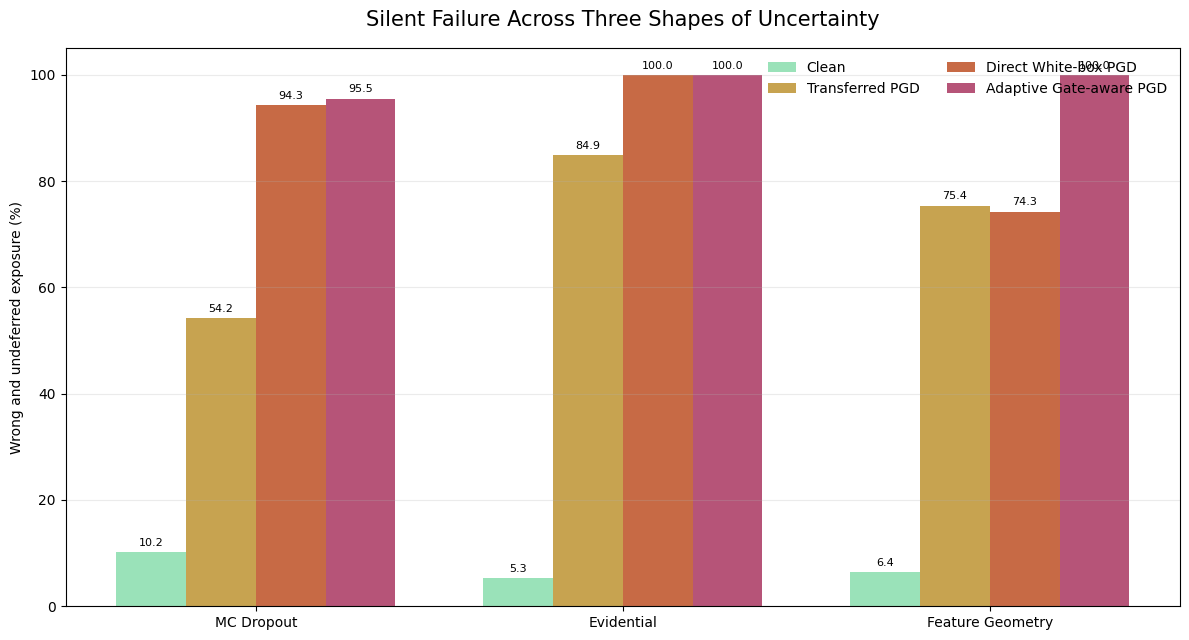

Saved essay10_results_corrected/wrong_undeferred_comparison.png


In [21]:
# ─────────────────────────────────────────────────────────────
# Part T: Main Visualization
# ─────────────────────────────────────────────────────────────

plot_frame = publication_table.copy()

mechanism_order = [
    "MC Dropout",
    "Evidential",
    "Feature Geometry",
]

condition_order = [
    "Clean",
    "Transferred PGD",
    "Direct White-box PGD",
    "Adaptive Gate-aware PGD",
]

colors = {
    "Clean": "#9AE2B9",
    "Transferred PGD": "#C7A350",
    "Direct White-box PGD": "#C76A45",
    "Adaptive Gate-aware PGD": "#B65478",
}

x = np.arange(len(mechanism_order))
bar_width = 0.19

fig, ax = plt.subplots(figsize=(12, 6.5))

for condition_index, condition in enumerate(condition_order):
    values = []

    for mechanism in mechanism_order:
        value = plot_frame.loc[
            (
                plot_frame["Mechanism"] == mechanism
            )
            & (
                plot_frame["Condition"] == condition
            ),
            "Wrong and Undeferred",
        ].iloc[0]

        values.append(value)

    positions = (
        x
        + (
            condition_index
            - (len(condition_order) - 1) / 2
        )
        * bar_width
    )

    bars = ax.bar(
        positions,
        values,
        width=bar_width,
        label=condition,
        color=colors[condition],
    )

    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=3,
        fontsize=8,
    )

ax.set_title(
    "Silent Failure Across Three Shapes of Uncertainty",
    fontsize=15,
    pad=16,
)

ax.set_ylabel("Wrong and undeferred exposure (%)")
ax.set_xticks(x)
ax.set_xticklabels(mechanism_order)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, ncol=2)

fig.tight_layout()

figure_path = RESULTS_DIR / "wrong_undeferred_comparison.png"
fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(f"Saved {figure_path}")


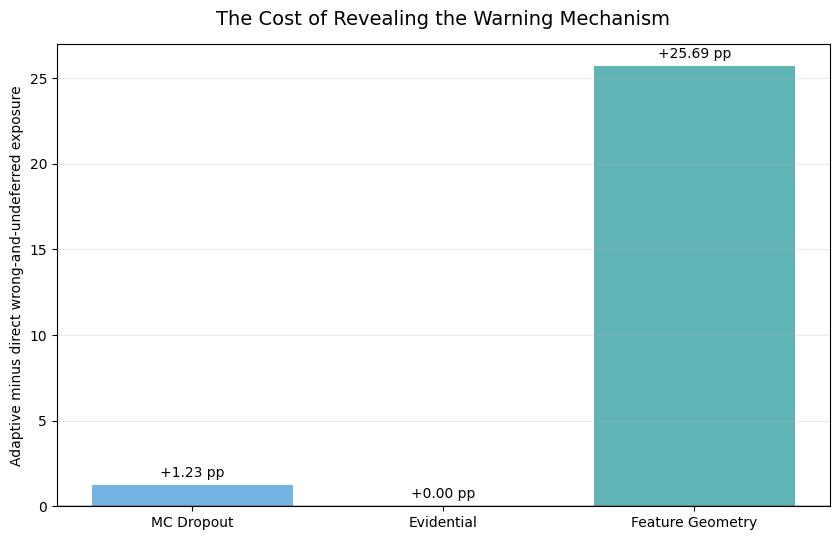

Saved essay10_results_corrected/awareness_gap.png


In [22]:
# ─────────────────────────────────────────────────────────────
# Part U: Awareness-Gap Visualization
# ─────────────────────────────────────────────────────────────

gap_plot = gap_results.copy()

gap_plot["Mechanism"] = gap_plot["mechanism"].map(
    display_names
)

fig, ax = plt.subplots(figsize=(8.5, 5.5))

bars = ax.bar(
    gap_plot["Mechanism"],
    gap_plot["awareness_gap_pp"],
    color=["#73B4E2", "#B47CCC", "#61B4B6"],
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
)

ax.bar_label(
    bars,
    fmt="%+.2f pp",
    padding=4,
)

ax.set_title(
    "The Cost of Revealing the Warning Mechanism",
    fontsize=14,
    pad=14,
)

ax.set_ylabel(
    "Adaptive minus direct wrong-and-undeferred exposure"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

fig.tight_layout()

gap_figure_path = RESULTS_DIR / "awareness_gap.png"

fig.savefig(
    gap_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(f"Saved {gap_figure_path}")


In [23]:
# ─────────────────────────────────────────────────────────────
# Part V: Automatic Factual Summary
# ─────────────────────────────────────────────────────────────

print("\nESSAY #10 FACTUAL SUMMARY")
print("=" * 72)

for mechanism in models:
    display_name = display_names[mechanism]

    mechanism_results = final_results[
        final_results["mechanism"] == mechanism
    ].set_index("condition")

    direct = mechanism_results.loc["direct_whitebox"]
    adaptive = mechanism_results.loc["adaptive"]

    awareness_gap = (
        adaptive["wrong_undeferred"]
        - direct["wrong_undeferred"]
    )

    deferral_change = (
        adaptive["deferral_rate"]
        - direct["deferral_rate"]
    )

    print(f"\n{display_name}")
    print(
        f"  Direct white-box wrong-and-undeferred: "
        f"{direct['wrong_undeferred']:.2f}%"
    )
    print(
        f"  Adaptive wrong-and-undeferred: "
        f"{adaptive['wrong_undeferred']:.2f}%"
    )
    print(
        f"  Awareness gap: {awareness_gap:+.2f} percentage points"
    )
    print(
        f"  Deferral change under adaptive knowledge: "
        f"{deferral_change:+.2f} percentage points"
    )

    if awareness_gap > 0 and deferral_change < 0:
        interpretation = (
            "The adaptive attack increased silent exposure while "
            "reducing the mechanism's willingness to defer."
        )
    elif awareness_gap > 0:
        interpretation = (
            "The adaptive attack increased silent exposure, but it "
            "did not clearly reduce deferral."
        )
    elif deferral_change < 0:
        interpretation = (
            "The adaptive attack reduced deferral, but this did not "
            "produce a larger wrong-and-undeferred rate."
        )
    else:
        interpretation = (
            "Knowledge of the gate did not produce a larger silent-"
            "failure exposure under this configuration."
        )

    print(f"  Interpretation: {interpretation}")



ESSAY #10 FACTUAL SUMMARY

MC Dropout
  Direct white-box wrong-and-undeferred: 94.28%
  Adaptive wrong-and-undeferred: 95.51%
  Awareness gap: +1.23 percentage points
  Deferral change under adaptive knowledge: -1.23 percentage points
  Interpretation: The adaptive attack increased silent exposure while reducing the mechanism's willingness to defer.

Evidential
  Direct white-box wrong-and-undeferred: 100.00%
  Adaptive wrong-and-undeferred: 100.00%
  Awareness gap: +0.00 percentage points
  Deferral change under adaptive knowledge: +0.00 percentage points
  Interpretation: Knowledge of the gate did not produce a larger silent-failure exposure under this configuration.

Feature Geometry
  Direct white-box wrong-and-undeferred: 74.27%
  Adaptive wrong-and-undeferred: 99.96%
  Awareness gap: +25.69 percentage points
  Deferral change under adaptive knowledge: -25.69 percentage points
  Interpretation: The adaptive attack increased silent exposure while reducing the mechanism's willingne

In [24]:
# ─────────────────────────────────────────────────────────────
# Part W: Save Complete Experiment Metadata
# ─────────────────────────────────────────────────────────────

metadata = {
    "seed": SEED,
    "device": str(DEVICE),
    "epochs": EPOCHS,
    "epsilon": EPSILON,
    "epsilon_pixels": EPSILON * 255,
    "step_size": STEP_SIZE,
    "step_size_pixels": STEP_SIZE * 255,
    "pgd_steps": PGD_STEPS,
    "mc_attack_passes": MC_ATTACK_PASSES,
    "mc_evaluation_passes": MC_EVAL_PASSES,
    "target_clean_deferral": TARGET_DEFERRAL,
    "calibration_size": calibration_size,
    "attack_development_size": attack_dev_size,
    "lambda_tuning_examples": len(tuning_dataset),
    "final_evaluation_size": evaluation_size,
    "lambda_candidates": LAMBDA_CANDIDATES,
    "selected_lambdas": selected_lambdas,
    "calibration": calibration,
}

with open(
    RESULTS_DIR / "experiment_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(metadata, file, indent=2)

print(f"All outputs saved in: {RESULTS_DIR.resolve()}")


All outputs saved in: /content/essay10_results_corrected
